# 02 — Baseline Models

**Task:** regression, predicting Jakarta house listing prices in IDR.
**Model contract:** `city`, `building_area`, `bed_rooms`, `bath_rooms`, `carport`.
**Target transform:** `log1p(price)`, inverted once by `TransformedTargetRegressor`.

This notebook reproduces the baseline comparison using the same functions and split as
`src/train.py`. The test set is **not evaluated here**; it stays held out for the final
evaluation after model selection.

In [1]:
import json
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / "pyproject.toml").exists():
    if PROJECT_ROOT == PROJECT_ROOT.parent:
        raise RuntimeError("Project root not found")
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
from sklearn.model_selection import KFold

from src.train import (
    BASELINE_PATH,
    CV_FOLDS,
    FEATURES,
    RANDOM_STATE,
    TARGET,
    build_models,
    evaluate_model,
    load_data,
    split_data,
)

pd.set_option("display.width", 200)
df = load_data()
X_train, X_test, y_train, y_test = split_data(df)
cv = KFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)

print(f"Dataset: {len(df):,} rows")
print(f"Train:   {len(X_train):,} rows")
print(f"Test:    {len(X_test):,} rows (held out, not evaluated)")
print(f"Features: {FEATURES}")
print(f"Target:   {TARGET}")

Dataset: 9,401 rows
Train:   7,520 rows
Test:    1,881 rows (held out, not evaluated)
Features: ['city', 'building_area', 'bed_rooms', 'bath_rooms', 'carport']
Target:   price


## Preprocessing and validation design

Numeric features are median-imputed and Yeo-Johnson transformed. The transformation is
fitted **inside** each CV fold, so no validation-fold statistics leak into training.
`city` is imputed with the most frequent value and one-hot encoded with
`handle_unknown="ignore"`.

In [2]:
from src.train import build_preprocessor

build_preprocessor()

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

## 5-fold CV baseline comparison

In [3]:
results = {}
for name, model in build_models().items():
    print(f"Training {name} ...")
    results[name] = evaluate_model(model, X_train, y_train, cv)

table = pd.DataFrame(
    {
        "cv_mae": {name: results[name]["cv"]["mae"]["mean"] for name in results},
        "cv_rmse": {name: results[name]["cv"]["rmse"]["mean"] for name in results},
        "cv_r2": {name: results[name]["cv"]["r2"]["mean"] for name in results},
        "train_mae": {name: results[name]["train"]["mae"] for name in results},
        "train_r2": {name: results[name]["train"]["r2"] for name in results},
    }
).sort_values("cv_mae")

display(table)

print(f"\nBest baseline by CV MAE: {table.index[0]}")

Training dummy ...


Training ridge ...


Training random_forest ...


Training gradient_boosting ...


,cv_mae,cv_rmse,cv_r2,train_mae,train_r2
gradient_boosting,4.456061e+09,1.507058e+10,0.450480,4.063127e+09,0.663083
random_forest,4.540648e+09,1.494841e+10,0.457815,2.238790e+09,0.806819
ridge,4.671027e+09,1.544705e+10,0.417556,4.659364e+09,0.391510
dummy,7.541253e+09,2.086020e+10,-0.083791,7.541253e+09,-0.071827



Best baseline by CV MAE: gradient_boosting


In [4]:
saved = json.loads(BASELINE_PATH.read_text())
saved_table = pd.DataFrame(
    {
        "saved_cv_mae": {
            name: saved["models"][name]["cv"]["mae"]["mean"]
            for name in saved["models"]
        },
        "reproduced_cv_mae": {
            name: results[name]["cv"]["mae"]["mean"] for name in results
        },
    }
)
saved_table["abs_diff"] = (
    saved_table["reproduced_cv_mae"] - saved_table["saved_cv_mae"]
).abs()
display(saved_table)

print("Maximum reproduction difference (IDR):", f"{saved_table['abs_diff'].max():,.2f}")

,saved_cv_mae,reproduced_cv_mae,abs_diff
dummy,7.541253e+09,7.541253e+09,0.000000
ridge,4.671027e+09,4.671027e+09,0.000000
random_forest,4.540648e+09,4.540648e+09,0.000002
gradient_boosting,4.456061e+09,4.456061e+09,0.000000


Maximum reproduction difference (IDR): 0.00


## Baseline diagnosis

In [5]:
diagnosis = table[["cv_mae", "cv_r2", "train_mae", "train_r2"]].copy()
diagnosis["mae_gap_train_minus_cv"] = diagnosis["train_mae"] - diagnosis["cv_mae"]
diagnosis["r2_gap_train_minus_cv"] = diagnosis["train_r2"] - diagnosis["cv_r2"]
display(diagnosis.sort_values("cv_mae"))

,cv_mae,cv_r2,train_mae,train_r2,mae_gap_train_minus_cv,r2_gap_train_minus_cv
gradient_boosting,4.456061e+09,0.450480,4.063127e+09,0.663083,-3.929342e+08,0.212603
random_forest,4.540648e+09,0.457815,2.238790e+09,0.806819,-2.301858e+09,0.349004
ridge,4.671027e+09,0.417556,4.659364e+09,0.391510,-1.166331e+07,-0.026046
dummy,7.541253e+09,-0.083791,7.541253e+09,-0.071827,-9.536743e-07,0.011964


**Reading the table**

- Gradient Boosting has the lowest CV MAE, while Random Forest has a slightly lower CV RMSE
  and higher CV R². The differences are small.
- Random Forest has a large train-vs-CV gap, a clear overfitting signal. Gradient Boosting
  generalises better.
- The Dummy median baseline has negative CV R²: it is worse than predicting the mean.
- Ridge is stable after the Yeo-Johnson transformation; without it, extrapolation through
  `expm1` produced non-finite-scale predictions for extreme building areas.
- The test set is intentionally untouched at this stage.

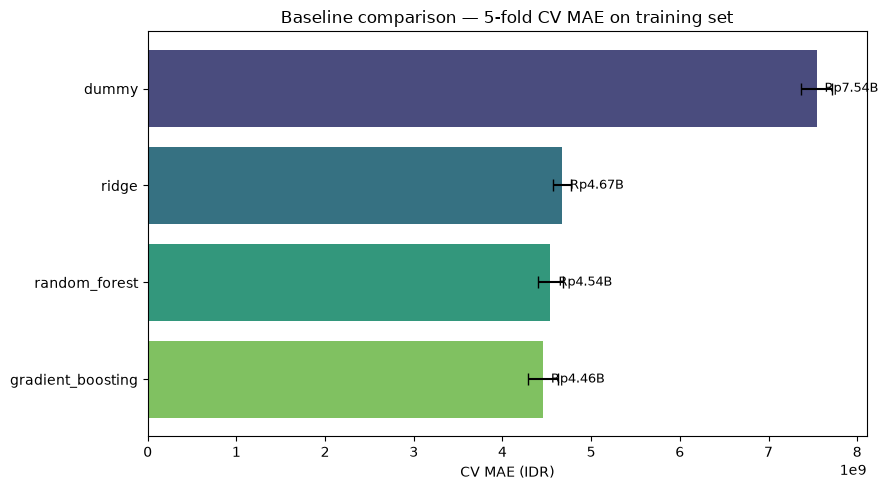

In [6]:
from IPython.display import Image, display as display_image

figure = PROJECT_ROOT / "results" / "figures" / "10_baseline_cv_mae.png"
if figure.exists():
    display_image(Image(filename=str(figure), width=800))
else:
    print("Run src/train.py to regenerate the baseline figure.")

## Next step

Tuning is performed in `src/train.py --tune` using only the training set. The model is
selected by CV MAE, and the test set is evaluated once after selection. Notebook
`03_evaluate_tune.ipynb` documents those saved results and the final evaluation.